# 3. Pan-Tompkins++ detection with Windowed delineation

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from _nb_helper import save_plot, setup_notebook
from scipy.signal import find_peaks

from ecg_waveform.config import load_yaml, save_yaml
from ecg_waveform.core import ECGAnnotation, Fiducials
from ecg_waveform.detection import build_delineator, build_detector
from ecg_waveform.detection.classical.common import moving_average
from ecg_waveform.evaluation import compute_metrics
from ecg_waveform.signal.preprocessing import (
    Preprocessor,
    butterworth_filter,
)
from ecg_waveform.signal.quality import SignalQualityAssessor
from ecg_waveform.signal.simulation import simulate_ecg
from ecg_waveform.visualization import (
    highlight_wave_bounds,
    plot_detection_results,
    plot_signal,
)

setup_notebook()

In [21]:
DURATION_SEC: float = 300.0
SAMPLE_RATE: int = 500
HEART_RATE_BPM: float = 60.0
HRV_STD_SEC: float = 0.03
RANDOM_SEED: int = 42

In [22]:
assessor_config = load_yaml("quality/quality_assessment_config.yaml")
assessor = SignalQualityAssessor.from_config(assessor_config)

In [23]:
preprocessor_config = load_yaml("preprocessing/preprocessing_pipeline.yaml")
preprocessor = Preprocessor.from_config(preprocessor_config)

In [24]:
raw_signal = simulate_ecg(
    duration_sec=DURATION_SEC,
    sample_rate=SAMPLE_RATE,
    heart_rate_bpm=HEART_RATE_BPM,
    hrv_std_sec=HRV_STD_SEC,
    seed=RANDOM_SEED,
)

In [25]:
clean_signal = preprocessor(raw_signal)

In [26]:
detector = build_detector("pan_tompkins_plus_plus")
result = detector.run(clean_signal)

print(detector)
print(result)

detected_points = result.annotation

PanTompkinsPlusPlusDetector(low_cutoff=5.0, high_cutoff=18.0, order=4, smoothing_window_s=0.06, integration_window_s=0.15, refractory_period_s=0.231, close_beat_period_s=0.36, slope_window_s=0.07, slope_ratio_threshold=0.6, searchback_gap_period_s=1.0, searchback_gap_ratio=1.66, weak_searchback_gap_period_s=1.4, weak_searchback_threshold_ratio=0.2, min_beats_for_rr_check=8, rr_history_size=8, threshold2_ratio=0.4, init_window_s=2.0)
DetectionResult(detector='PanTompkinsPlusPlusDetector', n_points=300, runtime=32.7 ms)


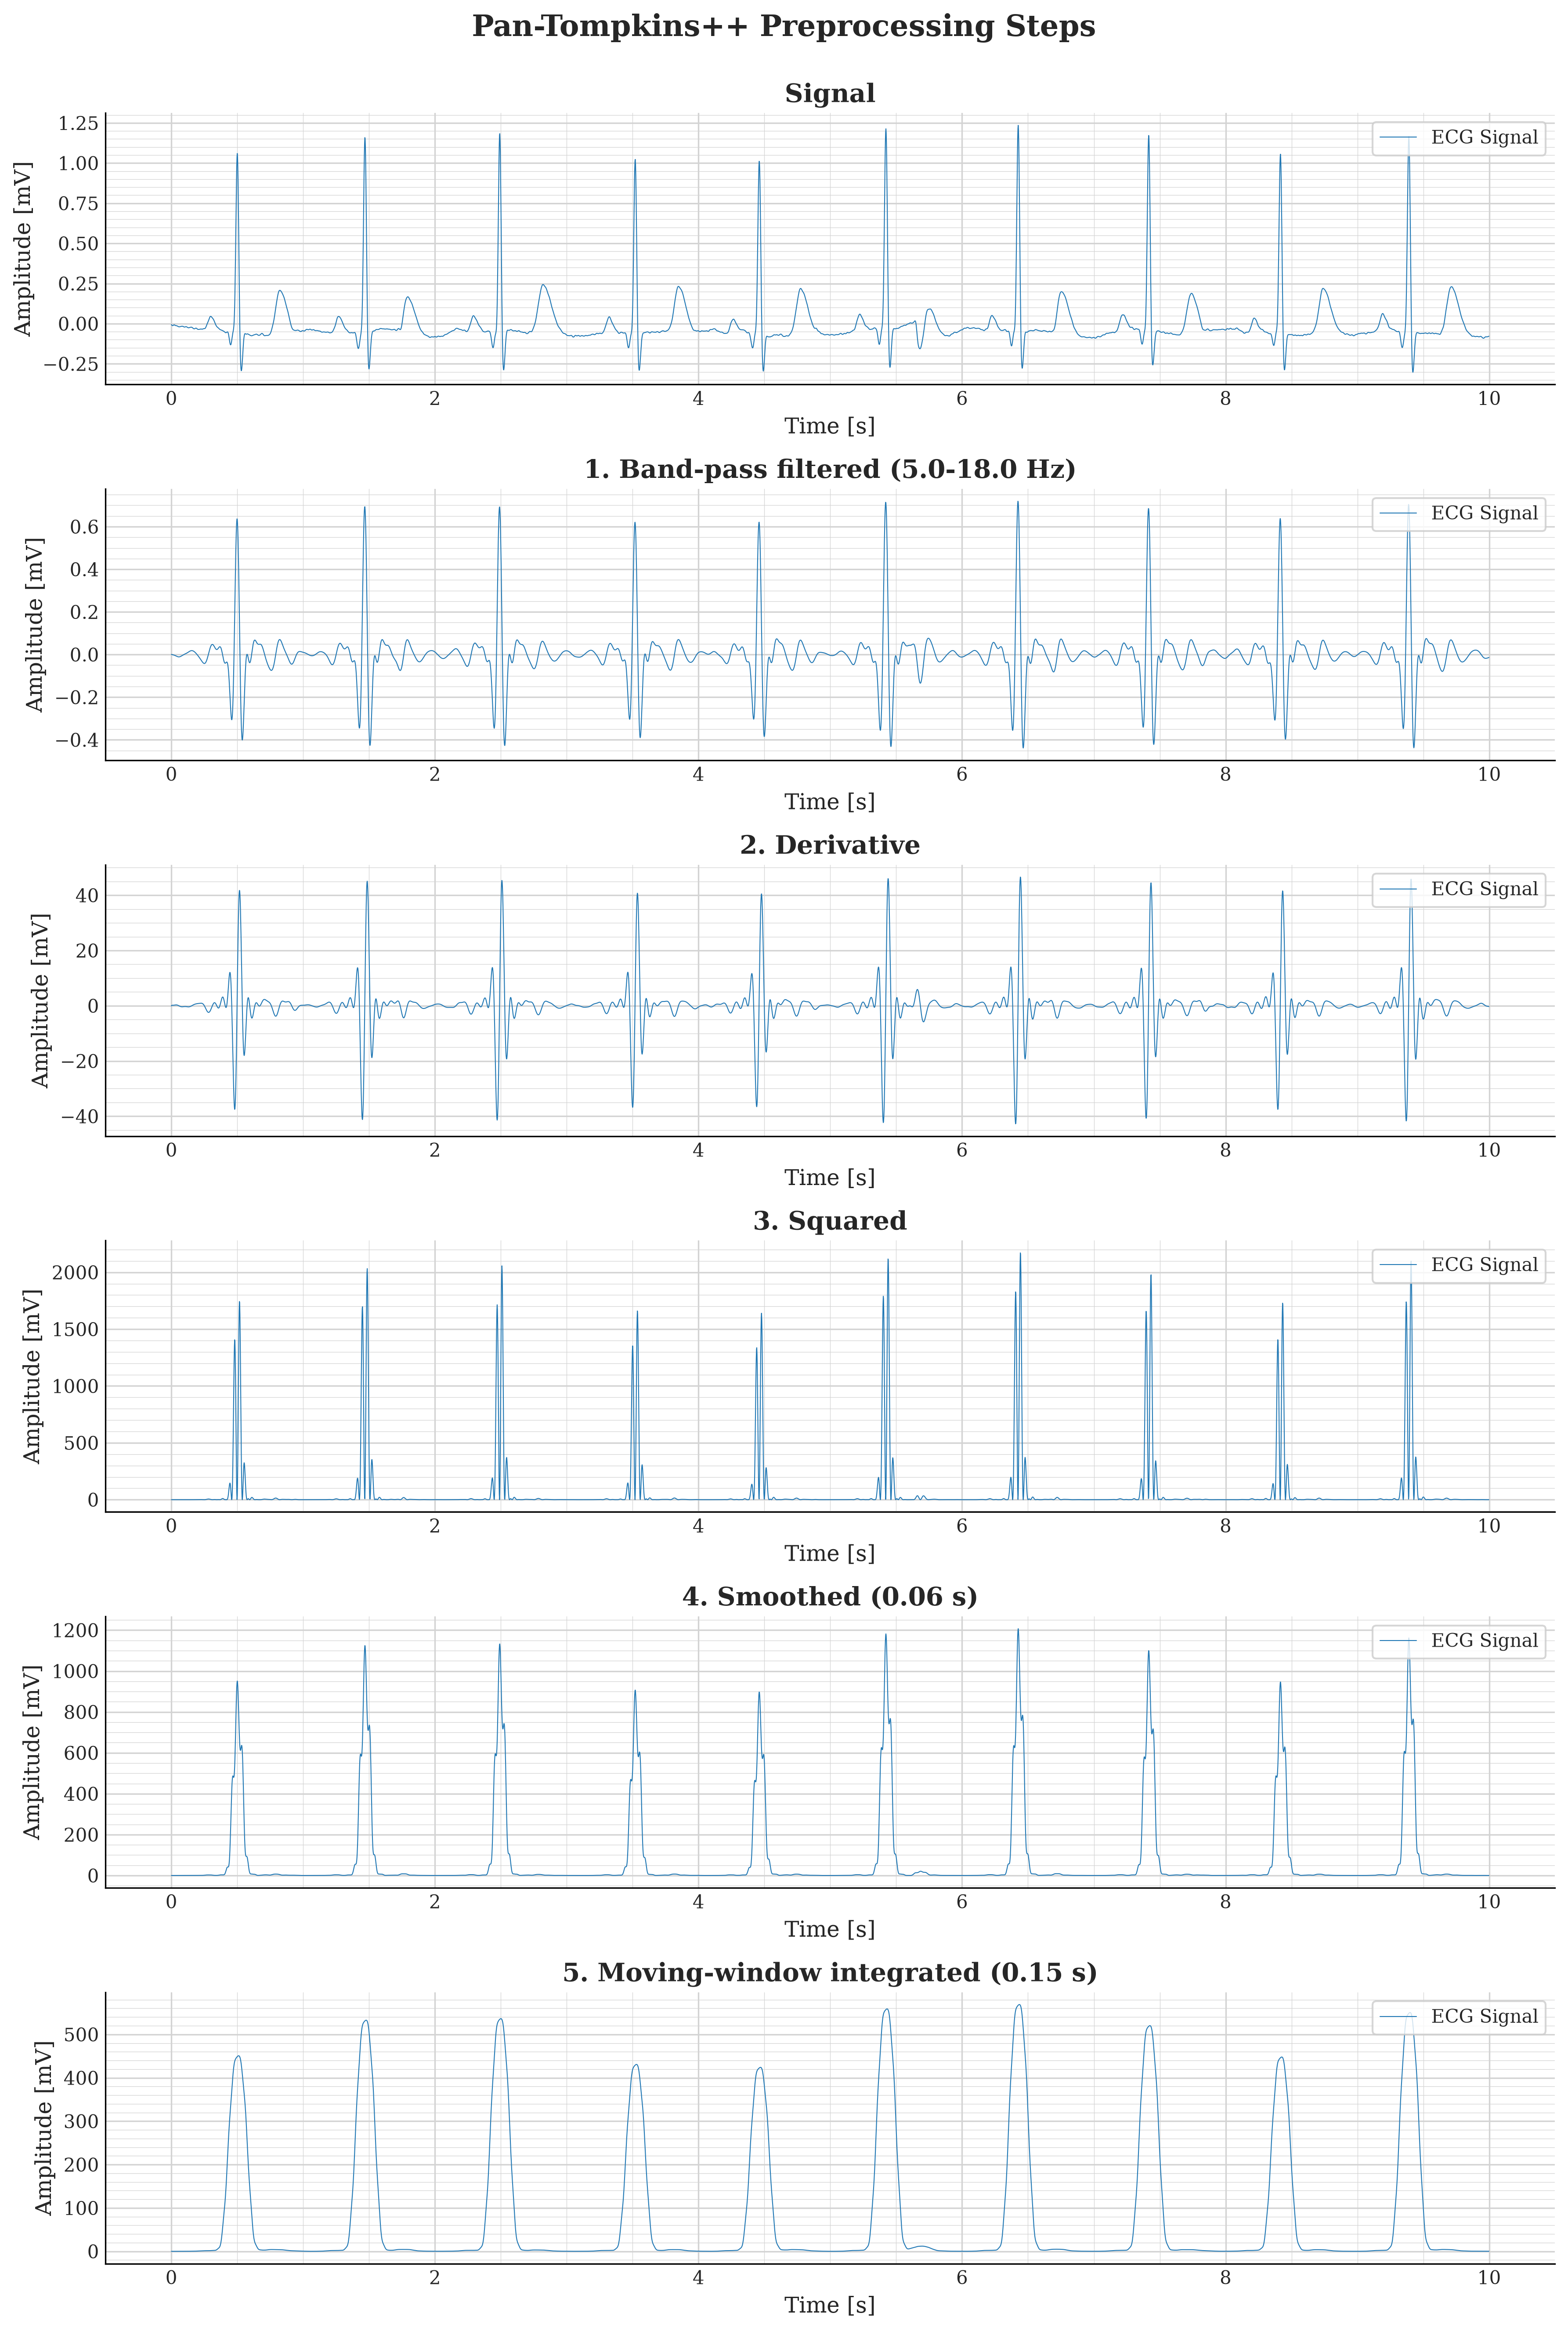

In [27]:
pt_steps = detector.preprocess(clean_signal)

STEPS = {
    "Signal": clean_signal,
    f"1. Band-pass filtered ({detector.low_cutoff}-{detector.high_cutoff} Hz)": pt_steps.bandpassed,
    "2. Derivative": pt_steps.derivative,
    "3. Squared": pt_steps.squared,
    f"4. Smoothed ({detector.smoothing_window_s} s)": pt_steps.smoothed,
    f"5. Moving-window integrated ({detector.integration_window_s} s)": pt_steps.integrated,
}

fig, axes = plt.subplots(len(STEPS), 1, figsize=(12, 3 * len(STEPS)))

for ax, (title, signal) in zip(axes, STEPS.items()):
    plot_signal(
        signal,
        start_sec=0,
        interval_sec=10,
        show_annotation=False,
        title=title,
        ax=ax,
    )

fig.suptitle("Pan-Tompkins++ Preprocessing Steps", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))

save_plot(fig, "Pan-Tompkins++ preprocessing steps")

Candidate peaks: 788, detected peaks: 300


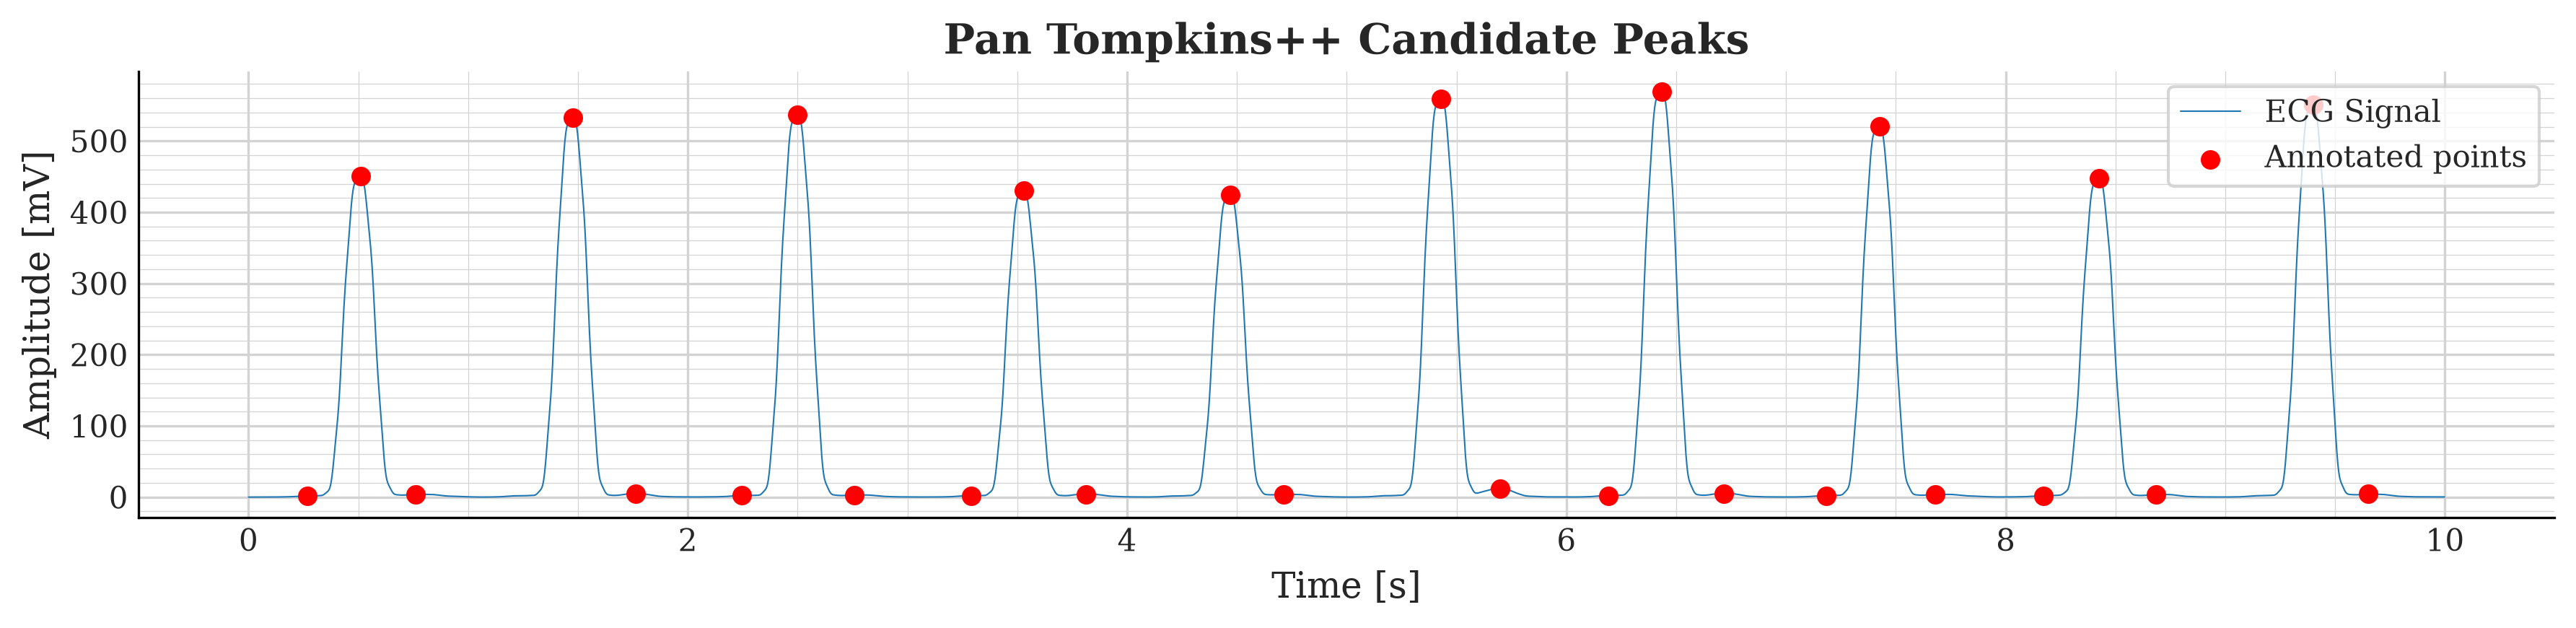

In [28]:
START_S, INTERVAL_S = 0, 10

integrated = pt_steps.integrated.sample
refractory_period = int(detector.refractory_period_s * SAMPLE_RATE)
candidate_peaks, _ = find_peaks(integrated, distance=refractory_period)

print(
    f"Candidate peaks: {len(candidate_peaks)}, detected peaks: {len(result.annotation)}"
)

candidates = ECGAnnotation(
    sample=candidate_peaks, symbol=np.array([""] * len(candidate_peaks))
)

fig, ax = plot_signal(
    pt_steps.integrated.with_annotation(candidates),
    start_sec=START_S,
    interval_sec=INTERVAL_S,
    title="Pan Tompkins++ Candidate Peaks",
)

Accepted above threshold: 300 / 300
Rejected above threshold: 0 / 488


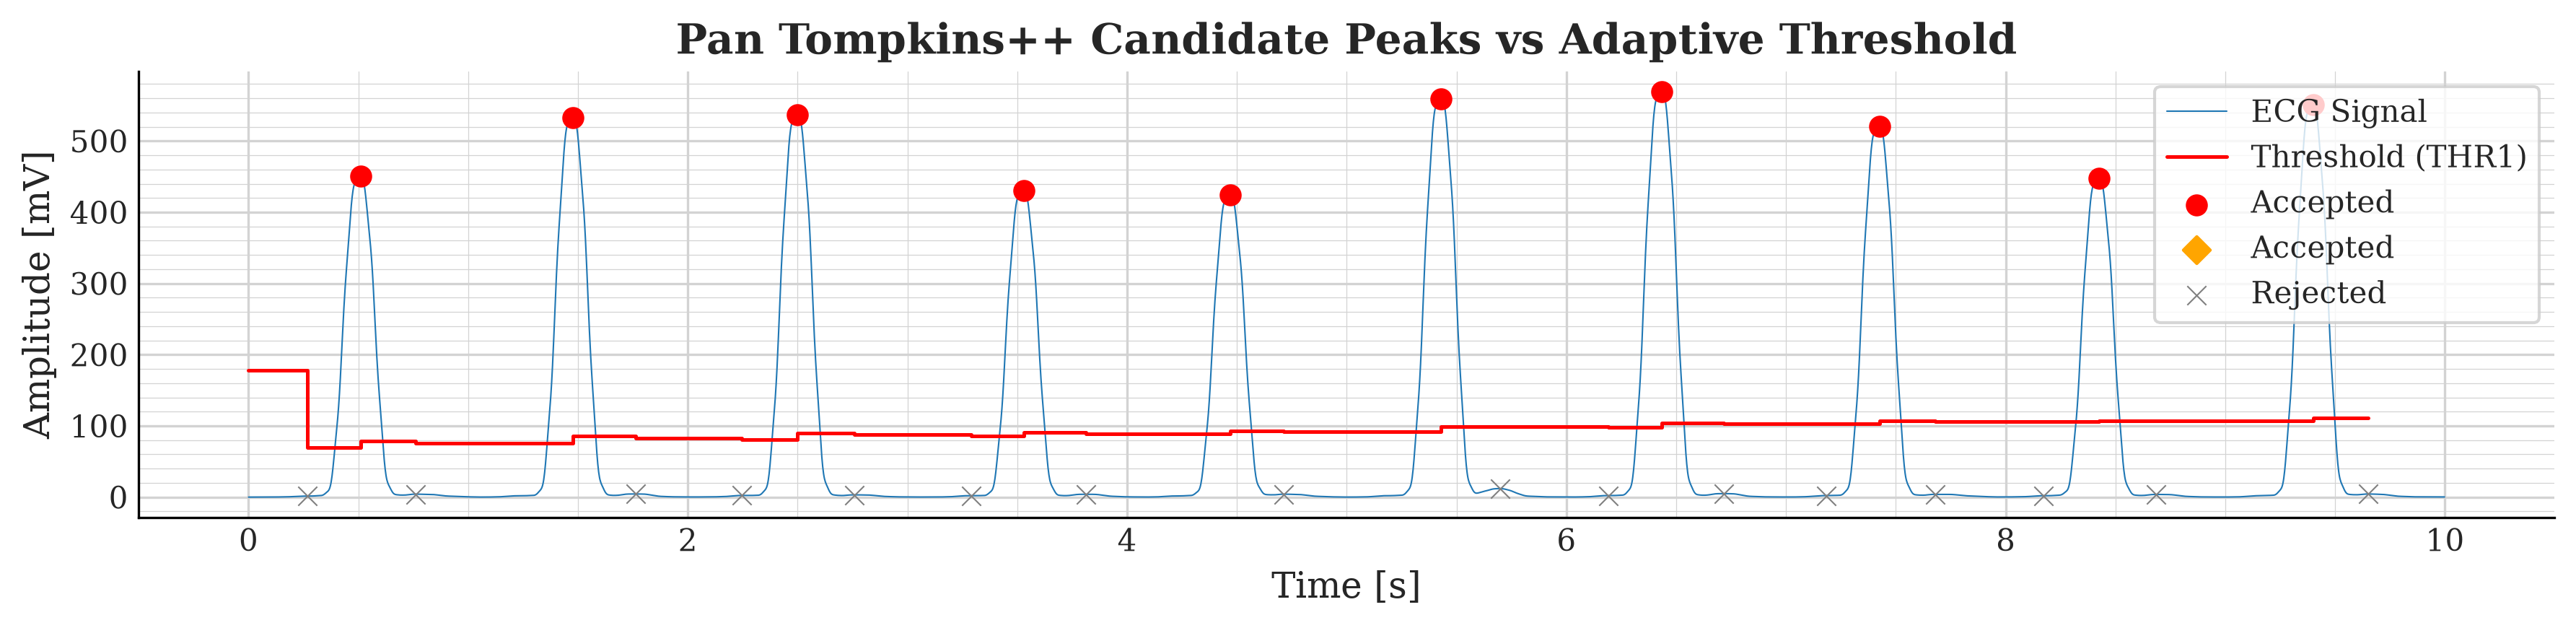

In [29]:
trace = {}
detector._detect_r_samples(pt_steps.bandpassed.sample, integrated, SAMPLE_RATE, trace=trace)

cand = np.array(trace["candidate"])
thr = np.array(trace["thr1"])
accepted = np.array(trace["accepted"])
rule = np.array(trace["rule"])
values = integrated[cand]

print(f"Accepted above threshold: {np.sum(accepted & (values > thr))} / {accepted.sum()}")
print(f"Rejected above threshold: {np.sum(~accepted & (values > thr))} / {(~accepted).sum()}")

START_S, INTERVAL_S = 0, 10
time = np.arange(len(integrated)) / SAMPLE_RATE
view = (time >= START_S) & (time < START_S + INTERVAL_S)
in_view = (cand / SAMPLE_RATE >= START_S) & (cand / SAMPLE_RATE < START_S + INTERVAL_S)

fig, ax = plt.subplots()

plot_signal(
    pt_steps.integrated,
    start_sec=START_S,
    interval_sec=INTERVAL_S,
    show_annotation=False,
    ax=ax,
    title="Pan Tompkins++ Candidate Peaks vs Adaptive Threshold"
)

threshold_time = cand / SAMPLE_RATE
in_view = (threshold_time >= START_S) & (
    threshold_time < START_S + INTERVAL_S
)

t = threshold_time[in_view]
y = thr[in_view]

if len(t):
    ax.step(
        np.r_[START_S, t],
        np.r_[y[0], y],
        where="pre",
        color="red",
        linewidth=1.2,
        label="Threshold (THR1)",
    )

for mask, kw in (
    (
        in_view & accepted & (rule == 1),
        {"color": "red", "marker": "o", "label": "Accepted"},
    ),
    (
        in_view & accepted & (rule == 2),
        {"color": "orange", "marker": "D", "label": "Accepted"},
    ),
    (
        in_view & ~accepted,
        {"color": "gray", "marker": "x", "label": "Rejected"},
    ),
):
    ax.scatter(cand[mask] / SAMPLE_RATE, values[mask], zorder=3, s=40, **kw)

ax.legend()
fig.tight_layout()

save_plot(fig, "Pan-Tompkins++ adaptive threshold")

,Symbol,Reference,Predicted,TP,FP,FN,Sensitivity,Positive Predictive Value,F1 Score,Detection Error Rate,Mean Absolute Timing Error,Mean Absolute Timing Error Std,Mean Timing Error,Timing Error Std
0,R,300,300,300,0,0,1.0,1.0,1.0,0.0,0.533333,0.884433,-0.533333,0.884433


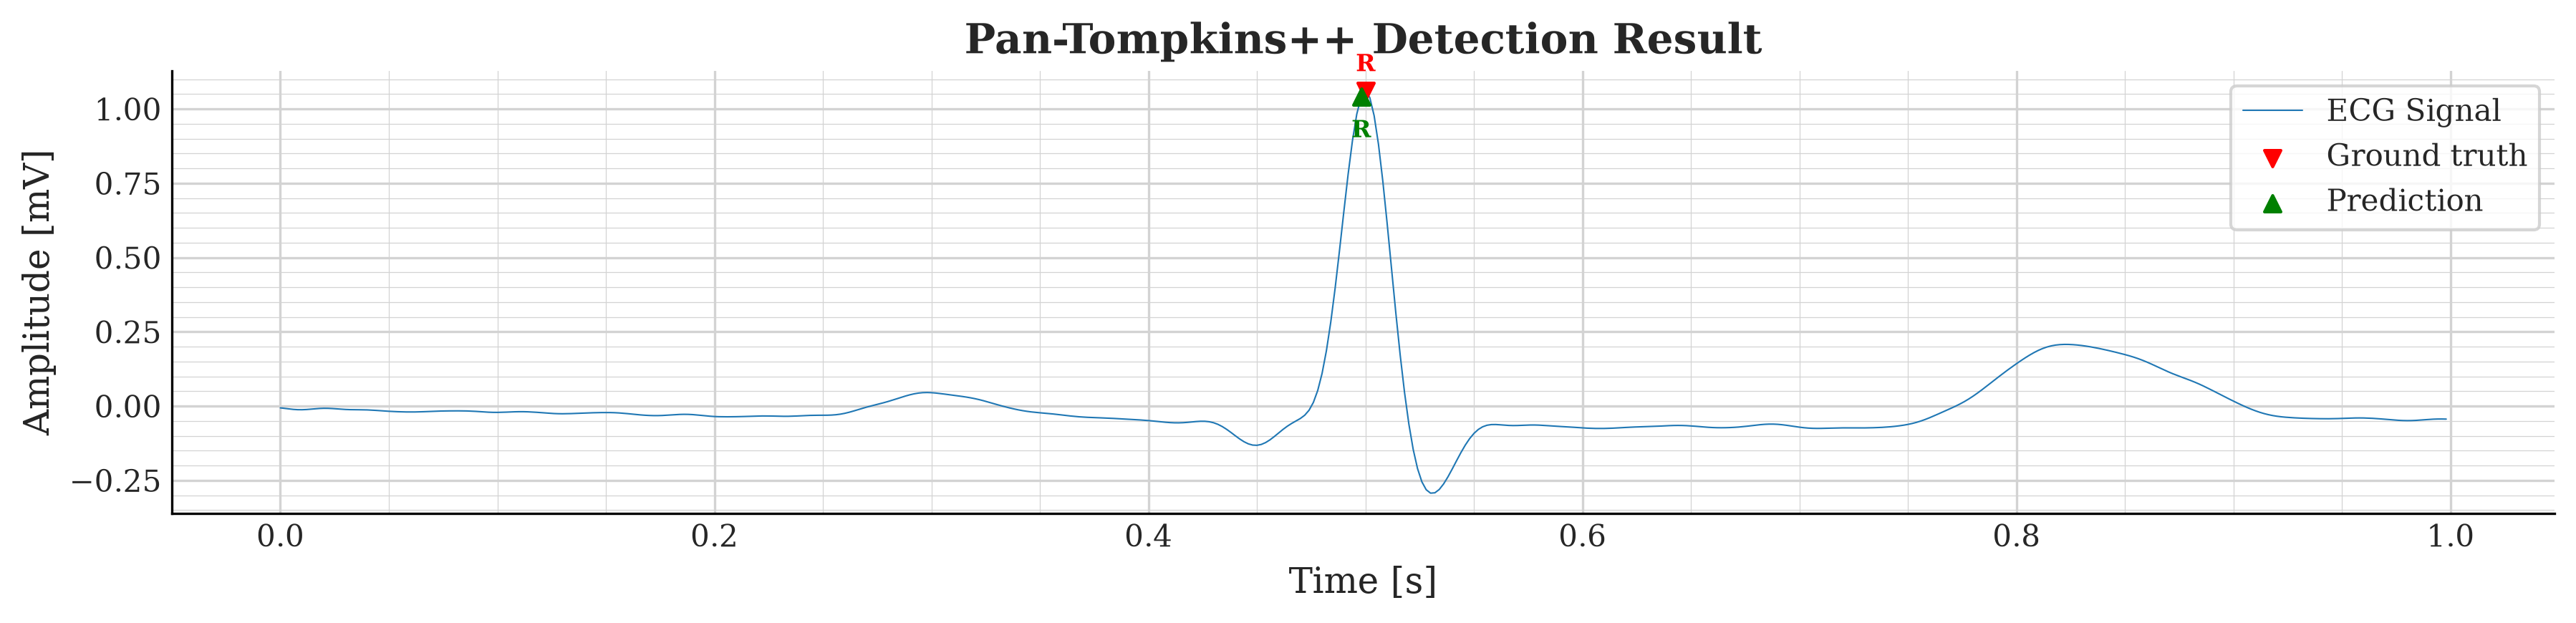

In [30]:
r_peaks = clean_signal.annotation.filter(Fiducials.R_PEAK)

metrics = compute_metrics(clean_signal, r_peaks, detected_points, Fiducials.R_PEAK)

metrics_df = pd.DataFrame([metrics.to_dict()])

display(metrics_df)

fig, ax = plot_detection_results(
    clean_signal.with_annotation(r_peaks),
    result.annotation,
    start_sec=0,
    interval_sec=1,
    title="Pan-Tompkins++ Detection Result",
)

save_plot(fig, "Pan-Tompkins++ detection result")

In [31]:
delineator = build_delineator("windowed")
result = delineator.run(clean_signal, detected_points.sample)

print(delineator)
print(result)

delineated_points = result.annotation

WindowedDelineator(qrs_low_cutoff=5.0, qrs_high_cutoff=18.0, qrs_order=4, qrs_search_window_s=0.12, qrs_slope_threshold_ratio=0.08, qrs_slope_smoothing_s=0.008, p_low_cutoff=0.5, p_high_cutoff=10.0, p_order=2, p_search_before_s=0.3, p_search_gap_s=0.02, p_min_gap_from_prev_beat_s=0.15, p_amplitude_threshold_ratio=0.08, p_noise_multiplier=2.0, p_boundary_persistence_s=0.006, t_low_cutoff=0.5, t_high_cutoff=8.0, t_order=2, t_search_after_s=0.5, t_search_gap_s=0.02, t_min_rr_fraction=0.5, t_qrs_guard_s=0.04, t_amplitude_threshold_ratio=0.08, t_noise_multiplier=2.0, t_boundary_persistence_s=0.008, minimum_wave_samples=5, boundary_smoothing_s=0.008)
DetectionResult(detector='WindowedDelineator', n_points=2924, runtime=472.5 ms)


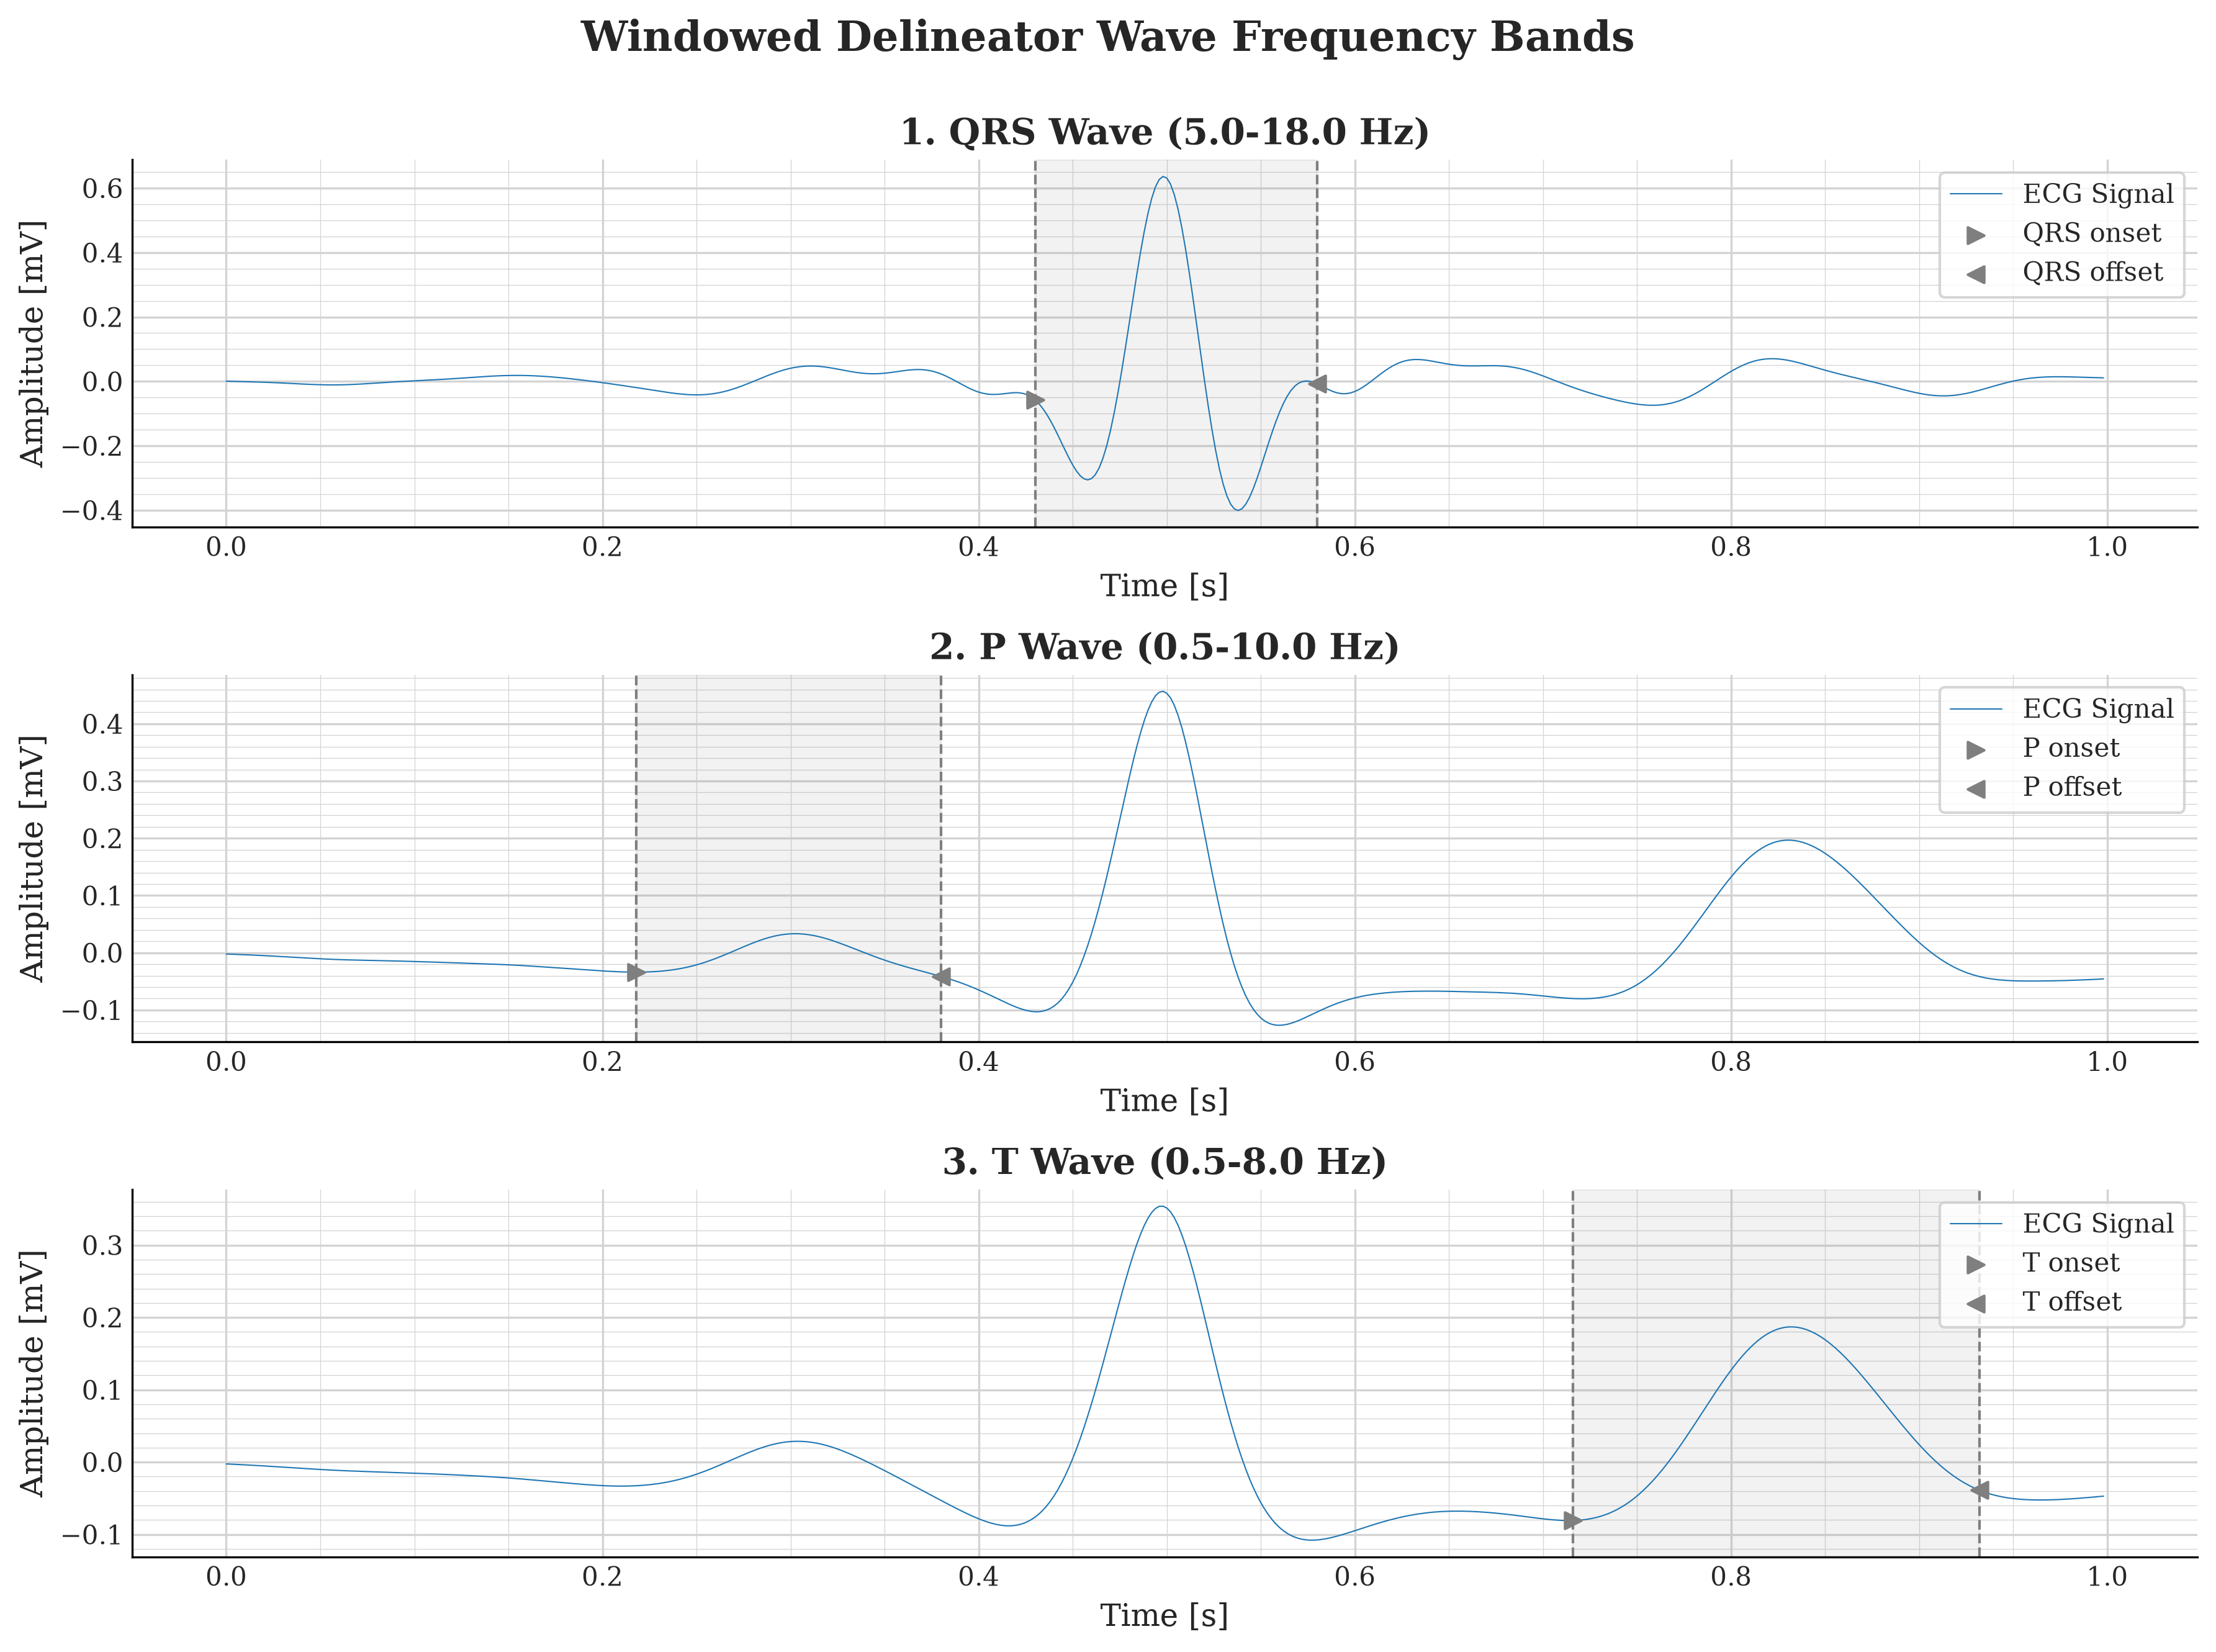

In [33]:
BANDS = {
    "QRS": (delineator.qrs_low_cutoff, delineator.qrs_high_cutoff, delineator.qrs_order),
    "P": (delineator.p_low_cutoff, delineator.p_high_cutoff, delineator.p_order),
    "T": (delineator.t_low_cutoff, delineator.t_high_cutoff, delineator.t_order),
}

filtered = {
    wave: butterworth_filter(clean_signal, low_cutoff=lo, high_cutoff=hi, order=order)
    for wave, (lo, hi, order) in BANDS.items()
}

START, INTERVAL = 0, 1

fig, axes = plt.subplots(len(filtered), 1, figsize=(12, 3 * len(filtered)))

for ax, (i, (wave, band_signal)) in zip(axes, enumerate(filtered.items(), start=1)):
    lo, hi, _ = BANDS[wave]
    plot_signal(
        band_signal,
        start_sec=START,
        interval_sec=INTERVAL,
        show_annotation=False,
        title=f"{i}. {wave} Wave ({lo}-{hi} Hz)",
        ax=ax,
    )
    highlight_wave_bounds(band_signal, wave, start_sec=START, interval_sec=INTERVAL, ax=ax)

fig.suptitle("Windowed Delineator Wave Frequency Bands", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.98))

save_plot(fig, "Windowed delineator wave frequency bands")

In [34]:
def beats_in_view(start_sec, interval_sec, margin_sec):
    lo, hi = (start_sec - margin_sec) * SAMPLE_RATE, (start_sec + interval_sec + margin_sec) * SAMPLE_RATE
    return [int(r) for r in detected_points.sample if lo <= r <= hi]


def last_in(samples, upper, max_back):
    hits = samples[(samples >= upper - max_back) & (samples <= upper)]
    return int(hits[-1]) if len(hits) else None


def first_in(samples, lower, max_fwd):
    hits = samples[(samples >= lower) & (samples <= lower + max_fwd)]
    return int(hits[0]) if len(hits) else None


def p_search_windows(beats):
    onsets = delineated_points.filter(Fiducials.QRS_ONSET).sample
    guard = int(delineator.qrs_search_window_s * SAMPLE_RATE)
    gap = int(delineator.p_search_gap_s * SAMPLE_RATE)
    span = int(delineator.p_search_before_s * SAMPLE_RATE)
    min_gap = int(delineator.p_min_gap_from_prev_beat_s * SAMPLE_RATE)

    windows = []
    for r in beats:
        onset = last_in(onsets, r, guard)
        end = max(0, (onset if onset is not None else r) - gap)
        start = max(0, end - span)
        i = int(np.searchsorted(detected_points.sample, r))
        if i > 0:
            start = max(start, int(detected_points.sample[i - 1]) + min_gap)
        windows.append((start, end))
    return windows


def t_search_windows(beats):
    offsets = delineated_points.filter(Fiducials.QRS_OFFSET).sample
    guard = int(delineator.qrs_search_window_s * SAMPLE_RATE)
    gap = int(delineator.t_search_gap_s * SAMPLE_RATE)
    qrs_guard = int(delineator.t_qrs_guard_s * SAMPLE_RATE)

    windows = []
    for r in beats:
        ofSAMPLE_RATEet = first_in(offsets, r, guard)
        start = max(0, (ofSAMPLE_RATEet if ofSAMPLE_RATEet is not None else r) + gap)
        end = r + int(delineator.t_search_after_s * SAMPLE_RATE)
        i = int(np.searchsorted(detected_points.sample, r))
        if i + 1 < len(detected_points.sample):
            next_r = int(detected_points.sample[i + 1])
            end = min(end, r + int(delineator.t_min_rr_fraction * (next_r - r)), next_r - qrs_guard)
        windows.append((start, min(len(clean_signal), end)))
    return windows


def overlay_wave_search(ax, band_signal, windows, ratio, start_sec, interval_sec, name):
    view_lo, view_hi = start_sec * SAMPLE_RATE, (start_sec + interval_sec) * SAMPLE_RATE
    first = True
    for lo, hi in windows:
        vis_lo, vis_hi = max(lo, view_lo), min(hi, view_hi)
        if hi <= lo or vis_hi <= vis_lo:
            continue
        segment = band_signal.sample[lo:hi]
        baseline = float(np.median(segment))
        threshold = ratio * float(np.max(np.abs(segment - baseline)))

        ax.axvspan(vis_lo / SAMPLE_RATE, vis_hi / SAMPLE_RATE, color="gray", alpha=0.1,
                   label=f"{name} search window" if first else None)
        ax.hlines([baseline + threshold, baseline - threshold], vis_lo / SAMPLE_RATE, vis_hi / SAMPLE_RATE,
                  color="gray", linestyle="--", linewidth=1.5,
                  label=f"Baseline ± {ratio:g} × peak deviation" if first else None)
        first = False

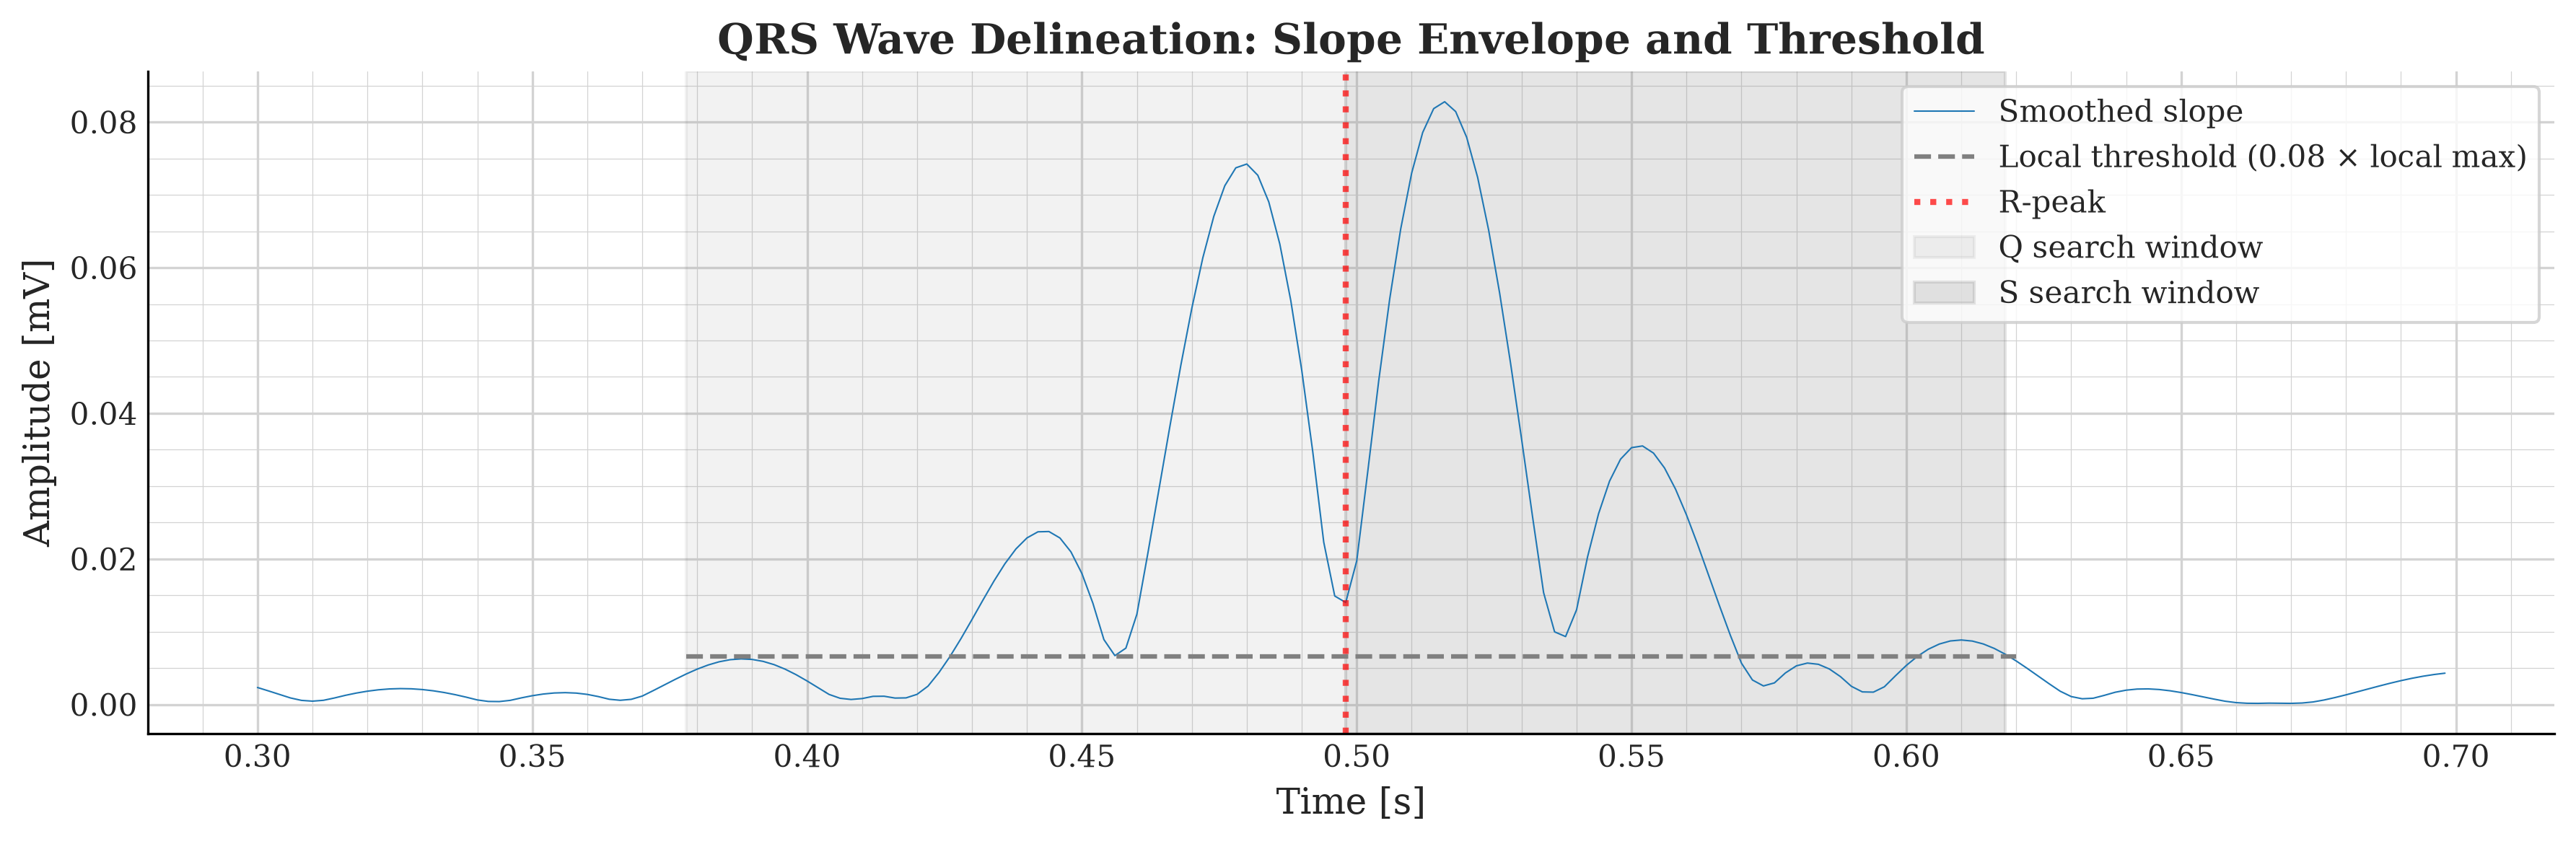

In [35]:
START, INTERVAL = 0.3, 0.4

qrs_signal = filtered["QRS"].with_annotation(
    delineated_points.filter(
        [
            Fiducials.QRS_ONSET,
            Fiducials.Q_PEAK,
            Fiducials.R_PEAK,
            Fiducials.S_PEAK,
            Fiducials.QRS_OFFSET,
        ]
    )
)

smoothing = max(1, int(delineator.qrs_slope_smoothing_s * SAMPLE_RATE))
slope = qrs_signal.with_sample(
    moving_average(np.abs(np.gradient(qrs_signal.sample)), smoothing)
)

half = max(1, int(delineator.qrs_search_window_s * SAMPLE_RATE))

fig, ax = plt.subplots(figsize=(12, 4))

plot_signal(
    slope,
    start_sec=START,
    interval_sec=INTERVAL,
    show_annotation=False,
    ax=ax,
    label="Smoothed slope",
    title="QRS Wave Delineation: Slope Envelope and Threshold",
)

for k, r in enumerate(beats_in_view(START, INTERVAL, delineator.qrs_search_window_s)):
    left, right = max(0, r - half), min(len(clean_signal), r + half + 1)
    threshold = delineator.qrs_slope_threshold_ratio * slope.sample[left:right].max()

    ax.hlines(
        threshold,
        left / SAMPLE_RATE,
        right / SAMPLE_RATE,
        color="gray",
        linestyle="--",
        linewidth=1.5,
        label=f"Local threshold ({delineator.qrs_slope_threshold_ratio:g} × local max)"
        if k == 0
        else None,
    )
    ax.axvline(
        r / SAMPLE_RATE,
        color="red",
        linestyle=":",
        alpha=0.7,
        linewidth=2,
        label="R-peak" if k == 0 else None,
    )
    ax.axvspan(
        (r - half) / SAMPLE_RATE,
        r / SAMPLE_RATE,
        color="gray",
        alpha=0.1,
        label="Q search window" if k == 0 else None,
    )
    ax.axvspan(
        r / SAMPLE_RATE,
        (r + half) / SAMPLE_RATE,
        color="gray",
        alpha=0.2,
        label="S search window" if k == 0 else None,
    )

ax.legend()
fig.tight_layout()

save_plot(fig, "Windowed QRS wave delineator")

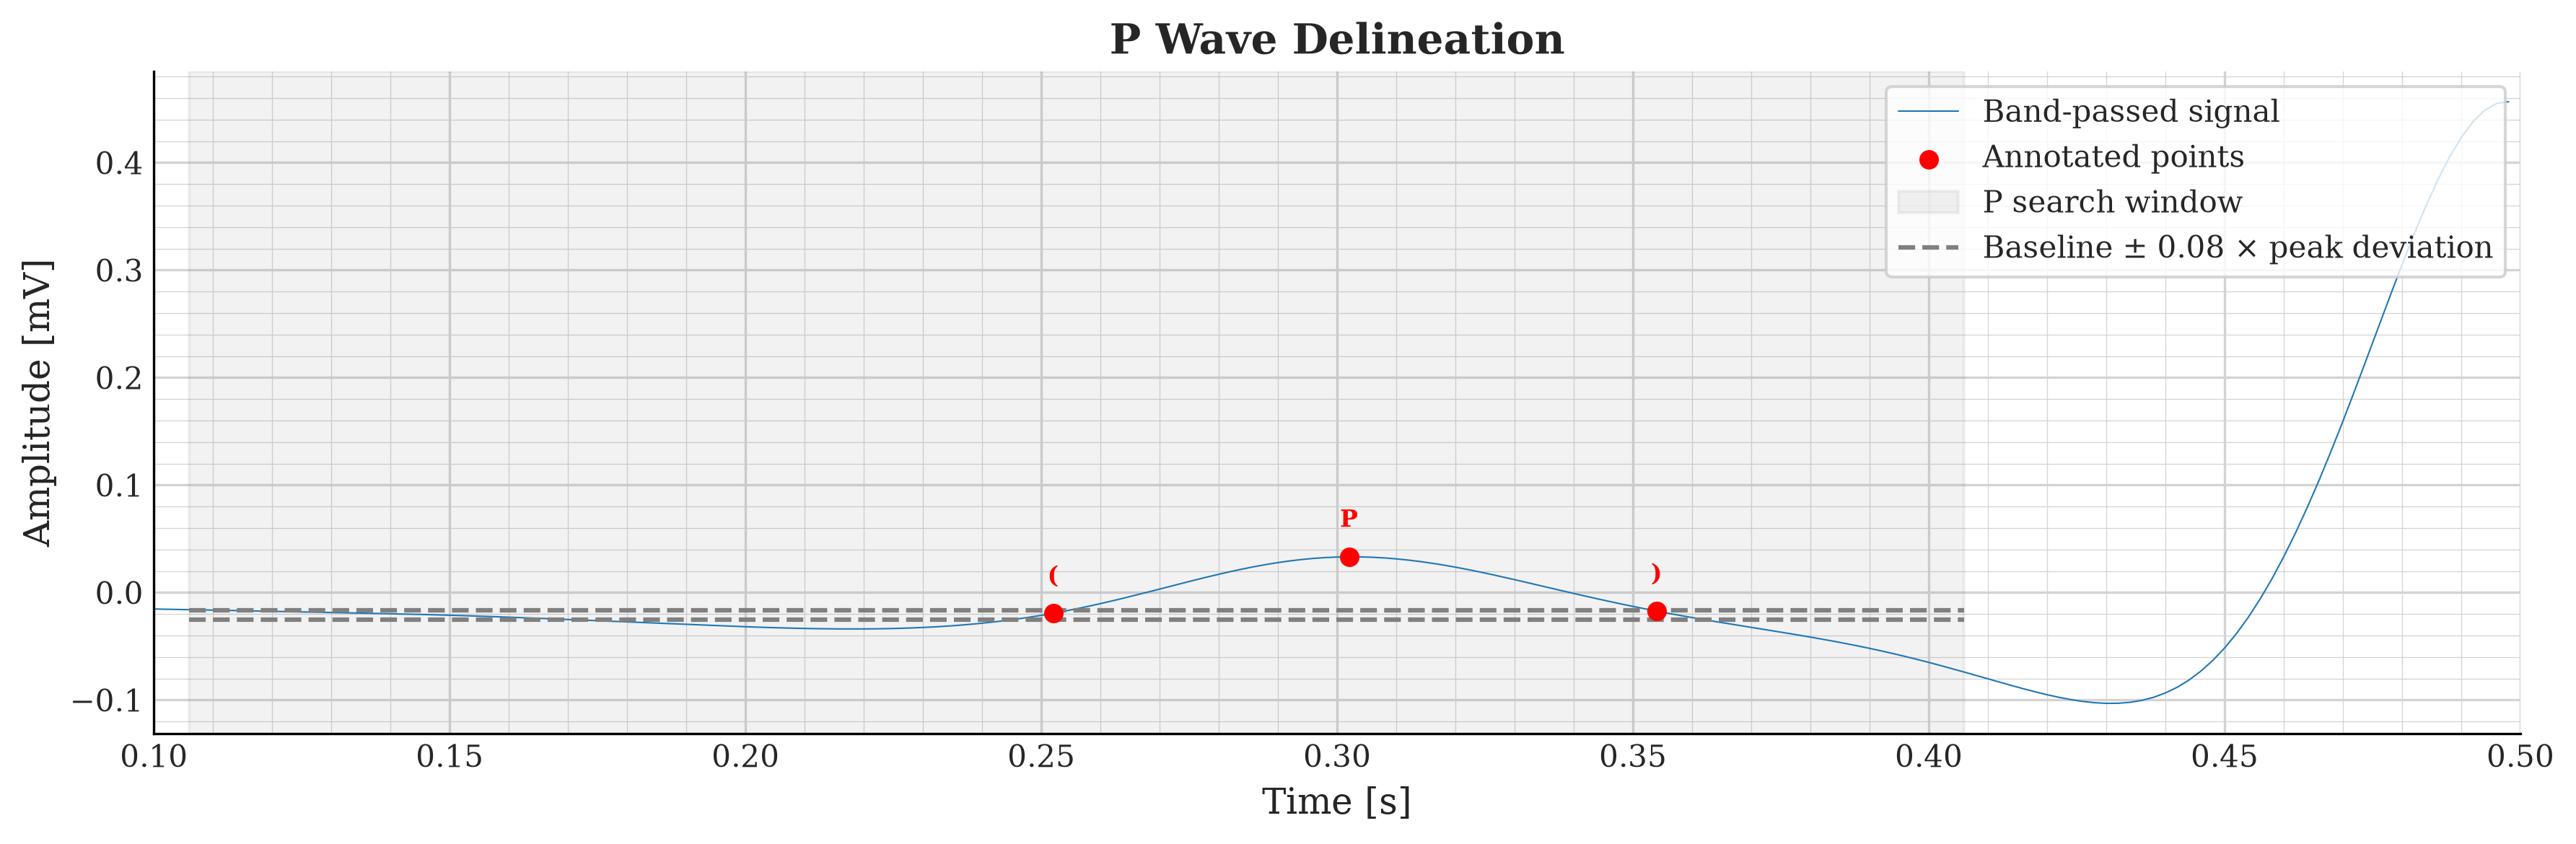

In [36]:
START, INTERVAL = 0.1, 0.4

p_signal = filtered["P"].with_annotation(
    delineated_points.filter([Fiducials.P_ONSET, Fiducials.P_PEAK, Fiducials.P_OFFSET])
)

fig, ax = plt.subplots(figsize=(12, 4))

plot_signal(
    p_signal,
    start_sec=START,
    interval_sec=INTERVAL,
    ax=ax,
    label="Band-passed signal", title="P Wave Delineation")

overlay_wave_search(
    ax, filtered["P"],
    p_search_windows(beats_in_view(START, INTERVAL, 1.0)),
    delineator.p_amplitude_threshold_ratio, START, INTERVAL, "P",
)

ax.set_xlim(START, START + INTERVAL)
ax.legend()
fig.tight_layout()

save_plot(fig, "Windowed P wave delineator")

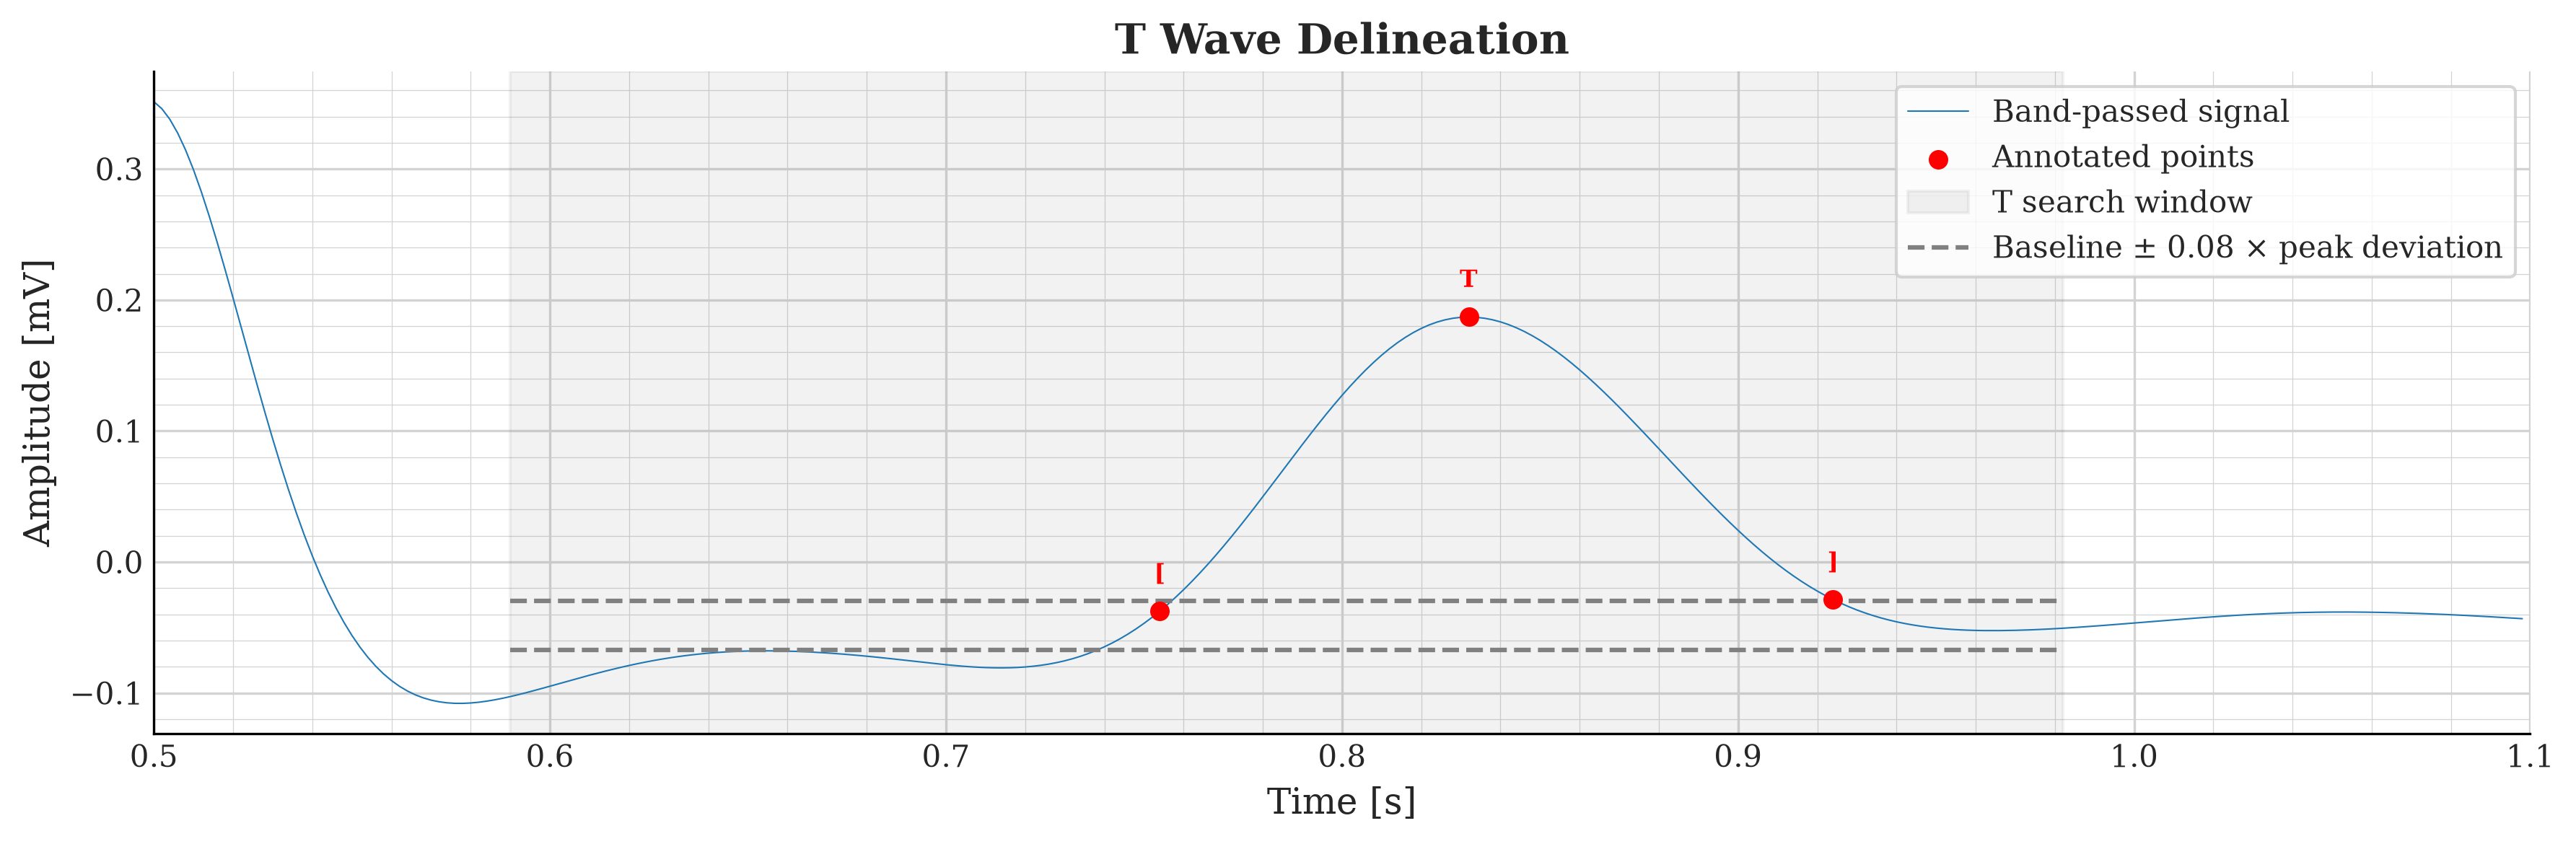

In [37]:
START, INTERVAL = 0.5, 0.6

t_signal = filtered["T"].with_annotation(
    delineated_points.filter([Fiducials.T_ONSET, Fiducials.T_PEAK, Fiducials.T_OFFSET])
)

fig, ax = plt.subplots(figsize=(12, 4))

plot_signal(t_signal, start_sec=START, interval_sec=INTERVAL, ax=ax,
            label="Band-passed signal", title="T Wave Delineation")

overlay_wave_search(
    ax, filtered["T"],
    t_search_windows(beats_in_view(START, INTERVAL, 1.0)),
    delineator.t_amplitude_threshold_ratio, START, INTERVAL, "T",
)

ax.set_xlim(START, START + INTERVAL)
ax.legend()
fig.tight_layout()

save_plot(fig, "Windowed T wave delineator")

,Symbol,Reference,Predicted,TP,FP,FN,Sensitivity,Positive Predictive Value,F1 Score,Detection Error Rate,Mean Absolute Timing Error,Mean Absolute Timing Error Std,Mean Timing Error,Timing Error Std
0,(,300,269,268,1,32,0.893333,0.996283,0.942004,0.11,31.141791,7.544547,30.320896,10.362173
1,P,300,300,270,30,30,0.900000,0.900000,0.900000,0.20,6.681481,1.741229,6.637037,1.903632
2,),300,269,268,1,32,0.893333,0.996283,0.942004,0.11,11.156716,7.733774,-9.111940,10.062610
3,{,300,300,300,0,0,1.000000,1.000000,1.000000,0.00,4.786667,1.030124,-4.786667,1.030124
4,Q,300,300,300,0,0,1.000000,1.000000,1.000000,0.00,8.960000,0.999200,8.960000,0.999200
5,S,300,300,300,0,0,1.000000,1.000000,1.000000,0.00,9.073333,1.010588,9.073333,1.010588
6,},300,300,300,0,0,1.000000,1.000000,1.000000,0.00,8.233333,0.886316,-8.220000,1.002464
7,[,300,293,283,10,17,0.943333,0.965870,0.954469,0.09,40.155477,6.566097,40.014134,7.378688
8,T,300,300,294,6,6,0.980000,0.980000,0.980000,0.04,11.693878,3.476084,11.435374,4.249959
9,],300,293,292,1,8,0.973333,0.996587,0.984823,0.03,7.143836,6.722982,-2.513699,9.482310


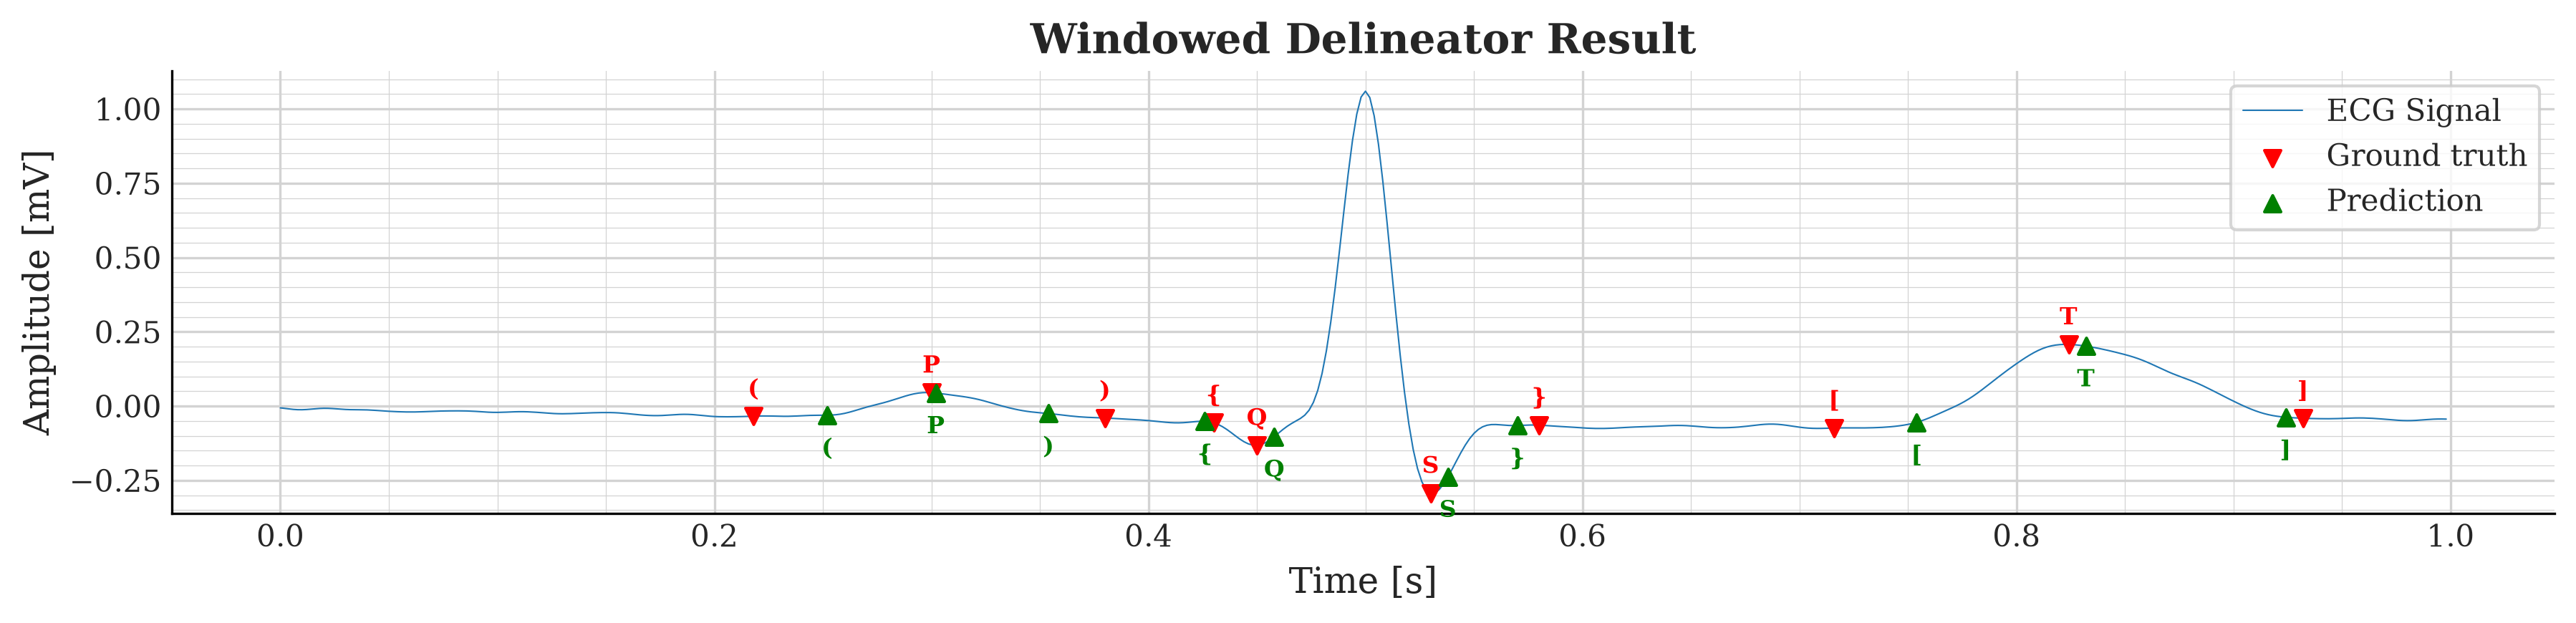

In [44]:
points = [f for f in Fiducials if f in delineator.supported_points]

metrics_df = pd.DataFrame(
    [compute_metrics(clean_signal, clean_signal.annotation, delineated_points, f).to_dict() for f in points]
)
display(metrics_df)

fig, ax = plot_detection_results(
    clean_signal.with_annotation(clean_signal.annotation.filter(points)),
    delineated_points,
    start_sec=0,
    interval_sec=1,
    title="Windowed Delineator Result",
)

save_plot(fig, "Windowed delineator result")